# Josiah Davis Notebook
# P2 Phase 4: Short-Token Allowlist

- Author: [Josiah Davis](https://github.com/jgdavis24/)
- Repository: [nlp-02-text-preprocessing-custom](https://github.com/jgdavis24/nlp-02-text-preprocessing-custom/)
- Purpose: Test a smarter minimum-length rule on the original example data.
- Date: 2026-11

## What I Changed and Why

The original example drops every token with 2 or fewer characters.
That removes noise, but it also removes short terms that can matter,
like state codes (PA, NJ, MI) or "ID" and "no".

Simply lowering the minimum to 2 lets in filler words like "we", "my", and "so".
So I added a **KEEP_SHORT allowlist** and a reusable `clean_tokens()` function,
then compared three rules on the **original** `data/text_data.txt`:

- **A.** original rule: 3+ characters
- **B.** all tokens with 2+ characters
- **C.** 3+ characters, plus anything in the allowlist

Stop words and punctuation handling are unchanged so only the length rule differs.

In [1]:
# Section 1. Setup and Imports

from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

print("Imports complete.")

Imports complete.


In [2]:
# Section 2. Read the Text Data (original example file)

NOTEBOOKS_PATH: Path = Path.cwd()
ROOT_PATH: Path = NOTEBOOKS_PATH.parent
DATA_PATH: Path = ROOT_PATH / "data"

input_path: Path = DATA_PATH / "text_data.txt"
text_list: list[str] = input_path.read_text(encoding="utf-8").splitlines()
text_list = [line.strip() for line in text_list if line.strip()]

raw_text: str = " ".join(text_list)
print(f"Loaded {len(text_list):,} text records from {input_path.name}.")

Loaded 5 text records from text_data.txt.


In [3]:
# Section 3. Tokenize, Lowercase, and Remove Punctuation (same as the example)

raw_tokens: list[str] = raw_text.split()
lower_text: str = raw_text.lower()
no_punct_text: str = re.sub(r"[^a-z0-9\s]", " ", lower_text)
tokens_no_punct: list[str] = no_punct_text.split()

print(f"Raw tokens: {len(raw_tokens):,}")
print(f"Tokens after punctuation removal: {len(tokens_no_punct):,}")

Raw tokens: 57
Tokens after punctuation removal: 57


In [4]:
# Section 4. Stop Words, Short-Token Allowlist, and Cleaning Rules

# Same stop word list as the original example.
STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

# NEW: short tokens worth keeping even though they are only 2 characters.
# State codes matter in sportsbook data, and "id" and "no" carry meaning.
KEEP_SHORT: set[str] = {"pa", "nj", "mi", "nv", "ny", "id", "no"}


def clean_tokens(
    tokens: list[str], min_len: int, keep_short: set[str] | None = None
) -> list[str]:
    """Return tokens that pass the length filter and are not stop words.

    Tokens in keep_short are kept even if they are shorter than min_len.
    """
    allow: set[str] = keep_short or set()
    return [
        token
        for token in tokens
        if (len(token) >= min_len or token in allow) and token not in STOP_WORDS
    ]


# Three rules to compare.
RULES: dict[str, dict] = {
    "A. original (3+ chars)": {"min_len": 3, "keep_short": None},
    "B. all 2+ chars": {"min_len": 2, "keep_short": None},
    "C. 3+ chars plus allowlist": {"min_len": 3, "keep_short": KEEP_SHORT},
}

results: dict[str, list[str]] = {
    name: clean_tokens(tokens_no_punct, **settings) for name, settings in RULES.items()
}

print("Cleaning rules defined.")

Cleaning rules defined.


In [5]:
# Section 5. Compare the Three Rules

summary_df: pl.DataFrame = pl.DataFrame(
    {
        "rule": list(results.keys()),
        "clean_tokens": [len(toks) for toks in results.values()],
        "unique_terms": [len(set(toks)) for toks in results.values()],
    }
)

print(f"Raw tokens: {len(raw_tokens):,}")
print(f"After lowercasing and punctuation removal: {len(tokens_no_punct):,}")
print()
print(summary_df)

Raw tokens: 57
After lowercasing and punctuation removal: 57

shape: (3, 3)
┌────────────────────────────┬──────────────┬──────────────┐
│ rule                       ┆ clean_tokens ┆ unique_terms │
│ ---                        ┆ ---          ┆ ---          │
│ str                        ┆ i64          ┆ i64          │
╞════════════════════════════╪══════════════╪══════════════╡
│ A. original (3+ chars)     ┆ 46           ┆ 38           │
│ B. all 2+ chars            ┆ 46           ┆ 38           │
│ C. 3+ chars plus allowlist ┆ 46           ┆ 38           │
└────────────────────────────┴──────────────┴──────────────┘


In [6]:
# Section 6. Which Terms Did Each Rule Add Compared to the Original?

baseline: set[str] = set(results["A. original (3+ chars)"])

for name, toks in results.items():
    if name.startswith("A."):
        continue
    added: list[str] = [t for t in toks if t not in baseline]
    if added:
        added_df: pl.DataFrame = (
            pl.DataFrame({"token": added})
            .group_by("token")
            .len()
            .sort(["len", "token"], descending=[True, False])
        )
        print(f"{name} added {len(added)} tokens:")
        print(added_df)
    else:
        print(f"{name} added no new tokens.")
    print()

B. all 2+ chars added no new tokens.

C. 3+ chars plus allowlist added no new tokens.



In [7]:
# Section 7. Audit the Short Tokens the Original Rule Drops

# Every 1-2 character token, and the reason it gets removed by the original rule.
short_df: pl.DataFrame = (
    pl.DataFrame({"token": [t for t in tokens_no_punct if len(t) <= 2]})
    .group_by("token")
    .len()
    .with_columns(
        pl.when(pl.col("token").is_in(list(STOP_WORDS)))
        .then(pl.lit("stop word"))
        .when(pl.col("token").is_in(list(KEEP_SHORT)))
        .then(pl.lit("allowlist keeps it"))
        .otherwise(pl.lit("too short"))
        .alias("reason")
    )
    .sort(["len", "token"], descending=[True, False])
)

print(f"Short tokens found: {short_df['len'].sum()} ({short_df.height} unique)")
with pl.Config(tbl_rows=30):
    print(short_df)

Short tokens found: 5 (5 unique)
shape: (5, 3)
┌───────┬─────┬───────────┐
│ token ┆ len ┆ reason    │
│ ---   ┆ --- ┆ ---       │
│ str   ┆ u64 ┆ str       │
╞═══════╪═════╪═══════════╡
│ as    ┆ 1   ┆ stop word │
│ be    ┆ 1   ┆ stop word │
│ in    ┆ 1   ┆ stop word │
│ of    ┆ 1   ┆ stop word │
│ to    ┆ 1   ┆ stop word │
└───────┴─────┴───────────┘


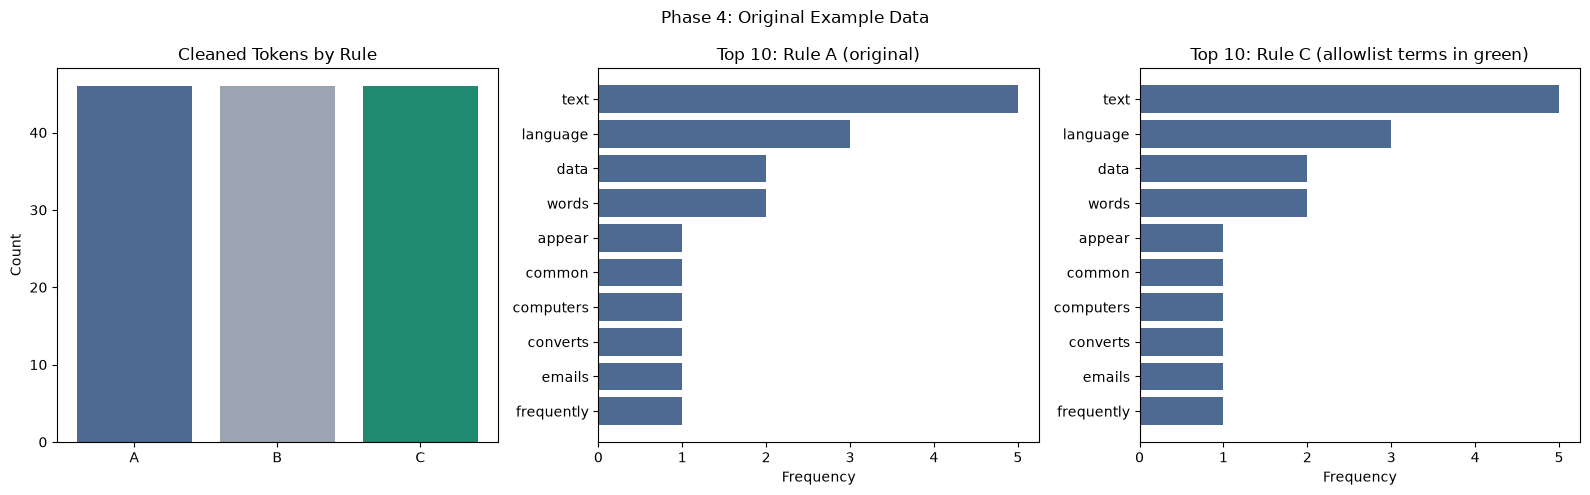

In [8]:
# Section 8. Visualize the Results

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

ax1.bar(
    ["A", "B", "C"],
    summary_df["clean_tokens"].to_list(),
    color=["#4C6A92", "#9AA5B1", "#1F8A70"],
)
ax1.set_title("Cleaned Tokens by Rule")
ax1.set_ylabel("Count")

top_a: pl.DataFrame = (
    pl.DataFrame({"token": results["A. original (3+ chars)"]})
    .group_by("token")
    .len()
    .sort(["len", "token"], descending=[True, False])
    .head(10)
)
top_c: pl.DataFrame = (
    pl.DataFrame({"token": results["C. 3+ chars plus allowlist"]})
    .group_by("token")
    .len()
    .sort(["len", "token"], descending=[True, False])
    .head(10)
)

ax2.barh(top_a["token"].to_list()[::-1], top_a["len"].to_list()[::-1], color="#4C6A92")
ax2.set_title("Top 10: Rule A (original)")
ax2.set_xlabel("Frequency")

colors_c: list[str] = [
    "#1F8A70" if t in KEEP_SHORT else "#4C6A92" for t in top_c["token"].to_list()
]
ax3.barh(
    top_c["token"].to_list()[::-1], top_c["len"].to_list()[::-1], color=colors_c[::-1]
)
ax3.set_title("Top 10: Rule C (allowlist terms in green)")
ax3.set_xlabel("Frequency")

fig.suptitle("Phase 4: Original Example Data")
plt.tight_layout()
plt.show()

## Interpretation

On the original example data, all three rules end up with the same counts
(check the table in Section 5). The audit in Section 7 explains why:
the short tokens in this file are mostly stop words like "is", "a", and "to",
so the stop word filter removes them before the length rule even matters.

Rule B would let in filler like "we" or "so" if they show up,
which is the problem with just lowering the minimum.
Rule C only adds terms I chose on purpose, so it's safer to use on new data.

The takeaway: a rule can be correct and still not change anything on a given dataset.
You need data where the rule actually matters to see its effect, which is what Phase 5 tests.